### Priors computing
We will test different priors and compute them here.

In [10]:
import sys
sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/')

import numpy as np
import matplotlib.pyplot as plt
import scipy 
import astropy.cosmology as acosmo
import astropy.units as u
from scipy.stats import gaussian_kde

from params import p_cosmology

### True redshift $z_{\text{true}}$

We will assume the true redshift follows a gaussian distribution centered the redshift from catalog matching $z_j$ with a certain uncertainty  $\sigma_j=0.5\cdot z_j$:
$$
z_{true} = Gauss(z_j,\sigma_j) = \frac{1}{\sqrt{2\pi\sigma_j^2}}\;exp\Big(\frac{-(z-z_j)^2}{2\sigma_j^2}\Big)
$$

In [4]:
def z_true_prior(z, z_j, sigma_j):
    '''
    Gaussian distribution of mean z_j and sigma sigma_j:

    Params:
    z: redshift to be evaluated
    z_j: mean of distribution
    sima_j: std deviation of the gaussian distribution
    '''
    
    return 1 / np.sqrt(2 * np.pi * sigma_j ** 2) * np.exp(-1 * (z - z_j) ** 2 / (2 * sigma_j ** 2))

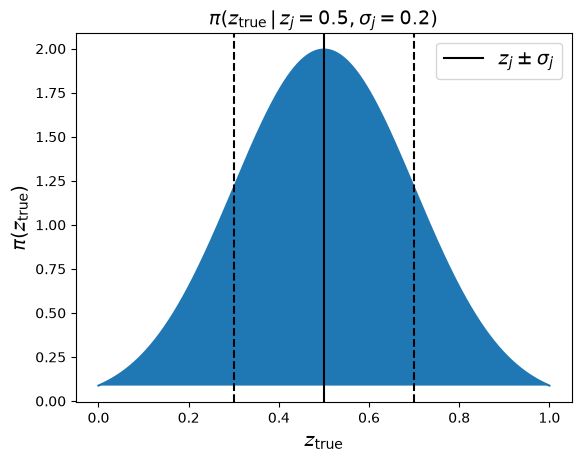

Integral of prior:  0.9875804863965112


In [5]:
z_j = 0.5
sigma_j = 0.2# * z_j
z_range = np.linspace(0, 1, 1000)
z_true =  z_true_prior(z_range, z_j, sigma_j)

plt.plot(z_range, z_true)
plt.fill(z_range, z_true)
plt.xlabel(r'$z_{\text{true}}$', fontsize=14)
plt.ylabel(r'$\pi(z_{\text{true}})$', fontsize=14)
plt.title(r'$\pi(z_{\text{true}}\,|\,z_j=0.5,\sigma_j=0.2)$', fontsize=14)
plt.axvline(z_j, label=r'$z_j\pm\sigma_j$', c='black')
plt.axvline(z_j + sigma_j, c='black', linestyle='dashed')
plt.axvline(z_j - sigma_j, c='black', linestyle='dashed')
plt.legend(fontsize=14)
plt.savefig('/Users/cristozilleruelo/Desktop/z_prior.png')#, bbox_to_inches='tight')
plt.show()

print('Integral of prior: ', scipy.integrate.trapezoid( z_true_prior(z_range, z_j, sigma_j), z_range))

### True distance

The true distance prior  for the **signal** case will be the convolution of:
$$
 \pi(d|S) = D_L(z_{true})\times R(z)\times d(z)^{-2}
$$

On the other hand, the true distance prior for the **background** case:
$$
\pi(d|B) = D_L(z_{true})\times R(z)
$$


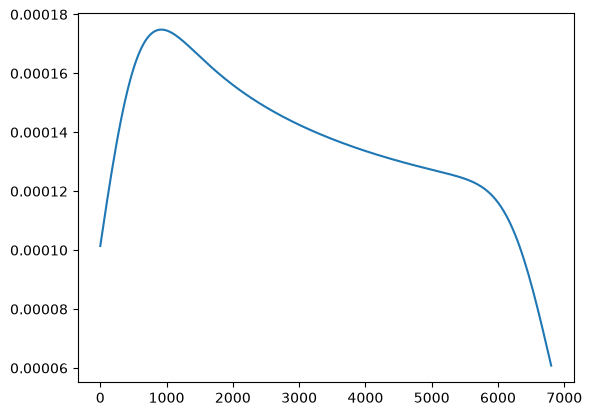

In [12]:
#distance
cosmo = acosmo.LambdaCDM(H0=p_cosmology['h0']* u.km / u.s / u.Mpc, 
                             Om0=p_cosmology['omega_M'],
                            Ode0=p_cosmology['omega_L'])#, Tcmb0=2.725 * u.K,

# distance_dist = cosmo.luminosity_distance(z_range) * z_true

distance_dist = cosmo.luminosity_distance(z_range)
z_norm = z_true / np.sum(z_true)
distance_sample = np.random.choice(distance_dist, p=z_norm, size=100000)

data = distance_dist
kde = gaussian_kde(data)

# Evaluate the PDF at specific points (e.g., across the range of your data)
x_vals = np.linspace(data.min(), data.max(), 200)
pdf_vals = kde(x_vals)

plt.plot(x_vals, pdf_vals)

# plt.hist(distance_sample)
# plt.show()


# plt.plot(z_range, distance_dist)
# plt.show()

# plt.plot(distance_dist, scipy.stats.Normal.pdf(distance_dist))
# plt.show()
# distance_prior = distance_dist / scipy.integrate.trapezoid(distance_dist, z_range)

# plt.plot(distance_dist, distance_prior)
# plt.xlabel(r'$d_L(z_{\text{true}}) \;[\text{Mpc}]$', fontsize=14)
# plt.ylabel(r'$\pi(d_L)$', fontsize=14)
# plt.title(r'$\pi(z_{\text{true}}\,|\,z_j=0.5,\sigma_j=0.2)$', fontsize=14)
# # plt.axvline(z_j, label=r'$z_j\pm\sigma_j$', c='black')
# # plt.axvline(z_j + sigma_j, c='black', linestyle='dashed')
# # plt.axvline(z_j - sigma_j, c='black', linestyle='dashed')
# plt.legend(fontsize=14)
# plt.savefig('/Users/cristozilleruelo/Desktop/z_prior.png')#, bbox_to_inches='tight')
# plt.show()


(array([206., 127.,  88.,  73.,  66.,  62.,  61.,  67.,  78., 172.]),
 array([   0.        ,  644.21610854, 1288.43221708, 1932.64832562,
        2576.86443416, 3221.08054271, 3865.29665125, 4509.51275979,
        5153.72886833, 5797.94497687, 6442.16108541]),
 <BarContainer object of 10 artists>)

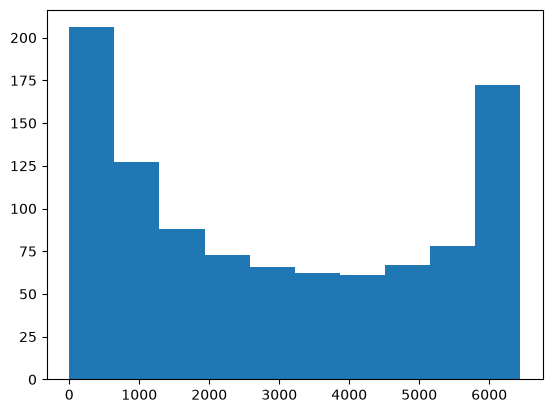

In [ ]:


data = distance_dist
# kde = gaussian_kde(data)

# # Evaluate the PDF at specific points (e.g., across the range of your data)
# x_vals = np.linspace(data.min(), data.max(), 200)
# pdf_vals = kde(x_vals)

# plt.plot(x_vals, pdf_vals)

plt.hist(distance_dist)

NameError: name 'acosmo' is not defined

### True classification type


### Contribution to the diffuse neutrino flux